# Island Arrivals | One-month-ahead tourism forecasts
Does a residual forest improve a simple autoregression for Sri Lankan arrivals? This notebook uses the shared training code that also produces the dashboard model. Run all cells from the extracted project folder.

## 1. Data provenance and quality
National monthly arrivals from the Sri Lanka Tourism Development Authority. The CSV records the bulletin URL beside each observation. April–November 2020 are dashes in the source. The other four months add to the published annual total of 507,704, so we encode those eight months as zero and retain the note for audit.

Monthly records: 132  | Annual 2020 total: 507704
note
dash reconciled to annual total      8
reported                           124


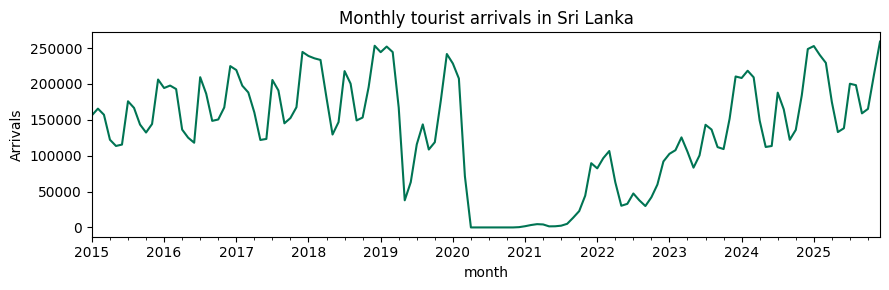

In [1]:
from pathlib import Path
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from train import dataset, train, FEATURES
from model import NAMES, predict_one, features
raw=pd.read_csv("data/arrivals.csv",parse_dates=["month"])
assert raw.month.is_unique and raw.arrivals.notna().all()
print("Monthly records:",len(raw)," | Annual 2020 total:",raw.loc[raw.month.dt.year==2020,"arrivals"].sum())
print(raw.groupby("note").size().to_string())
raw.plot(x="month",y="arrivals",figsize=(9,3),legend=False,color="#007453",title="Monthly tourist arrivals in Sri Lanka",ylabel="Arrivals")
plt.tight_layout()
plt.show()

## 2. Features and chronological folds
The target is the current month’s count. Lag 1, lag 2 and lag 12 use earlier observations. Sine and cosine encode the forecast month’s known calendar position. The first 12 months supply lag history. We use an expanding training window and freeze model parameters throughout each test year. Previous test months become observed lag inputs when their months have ended.

In [2]:
frame=dataset()
print(frame[["month","arrivals"]+FEATURES].head(3).to_string(index=False))
for year in (2023,2024,2025):
    h=frame[frame.month.dt.year<year]
    print(year,"| training rows:",len(h),"| final training month:",h.month.max().strftime("%Y-%m"),"| test months: 12")

     month  arrivals     lag1     lag2    lag12  season_sin   season_cos
2016-01-01    194280 206114.0 144147.0 156246.0    0.500000 8.660254e-01
2016-02-01    197697 194280.0 206114.0 165541.0    0.866025 5.000000e-01
2016-03-01    192841 197697.0 194280.0 157051.0    1.000000 6.123234e-17
2023 | training rows: 84 | final training month: 2022-12 | test months: 12
2024 | training rows: 96 | final training month: 2023-12 | test months: 12
2025 | training rows: 108 | final training month: 2024-12 | test months: 12


## 3. Fit, compare and export
Seasonal naive repeats lag 12. AR(1), the autoregressive special case of ARIMA(1,0,0), fits an intercept and slope to lag 1 by least squares. Random Forest and XGBoost use all five inputs. The hybrid adds a forest estimate of the AR training residual to the linear forecast. Stacking uses the RF and XGBoost forecasts as two inputs to a linear regression. Four expanding-window splits inside each training period generate out-of-fold forecasts. The meta-model fits only those forecasts and their observed targets. Both base learners are then refitted on the full training period for inference. Fixed settings are reused across folds. All outputs have a lower bound of zero. The comparison below uses the same windows and inputs available at each forecast date.

In [3]:
import inspect
from train import forest, fit, fit_base, fit_stacker
print(inspect.getsource(fit_stacker))
print(inspect.getsource(fit_base))
print(inspect.getsource(forest))
print(inspect.getsource(fit))
report=train()
print("Saved fitted parameters and chronological holdout predictions.")

def fit_stacker(x, y):
    # Every row seen by the meta-model was forecast by earlier-only base models.
    meta_inputs, targets = [], []
    for earlier, later in TimeSeriesSplit(n_splits=4).split(x):
        rf, boost = fit_base(x[earlier], y[earlier])
        meta_inputs.append(np.column_stack([rf.predict(x[later]), boost.predict(x[later])]))
        targets.extend(y[later])
    return LinearRegression().fit(np.vstack(meta_inputs), targets)

def fit_base(x, y):
    rf = forest().fit(x, y)
    boost = XGBRegressor(n_estimators=60, max_depth=2, learning_rate=.075, objective="reg:squarederror", n_jobs=1, random_state=42).fit(x, y)
    return rf, boost

def forest():
    return RandomForestRegressor(n_estimators=48, max_depth=5, min_samples_leaf=2, random_state=42, n_jobs=1)

def fit(frame):
    x, y = frame[FEATURES].to_numpy(), frame.arrivals.to_numpy()
    stacker = fit_stacker(x, y)
    rf, boost = fit_base(x, y)
    slope, intercept = np.polyfit(x[:, 0], y, 1)
    residuals = y - (

MAE (arrivals)
                 2023   2024   2025  All years
Seasonal naive  63944  47180  25755      45626
AR(1)           21767  31381  26941      26696
Random Forest   25114  31585  14896      23865
XGBoost         27481  29882  17662      25008
AR + Forest     16937  22580  10612      16710
Stacking        55844  48987  38200      47677
RMSE (arrivals)
                 2023   2024   2025  All years
Seasonal naive  72267  57346  27394      55563
AR(1)           28249  39855  34693      34593
Random Forest   32472  39393  16581      30990
XGBoost         34148  38681  18913      31728
AR + Forest     22209  29941  13116      22816
Stacking        61743  58248  42476      54800
Hybrid reduction against AR(1), percent:
2023         22.2
2024         28.0
2025         60.6
All years    37.4
dtype: float64


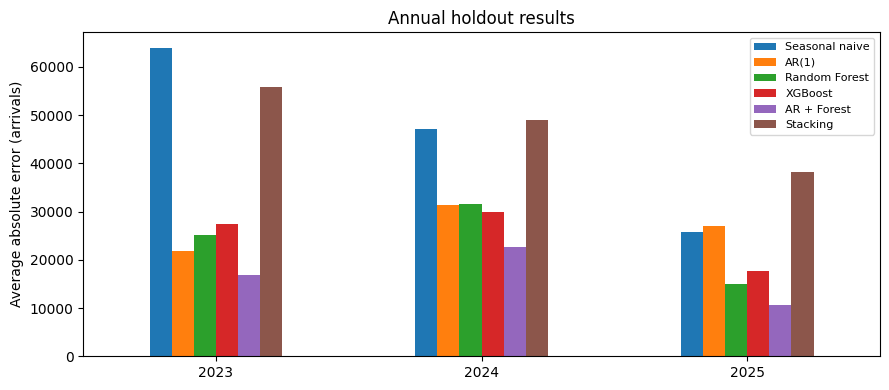

In [4]:
mae=pd.DataFrame({k:{n:s["MAE"] for n,s in v.items()} for k,v in report["scores"].items()})
rmse=pd.DataFrame({k:{n:s["RMSE"] for n,s in v.items()} for k,v in report["scores"].items()})
print("MAE (arrivals)"); print(mae.round().astype(int))
print("RMSE (arrivals)"); print(rmse.round().astype(int))
print("Hybrid reduction against AR(1), percent:"); print(((1-mae.loc["AR + Forest"]/mae.loc["AR(1)"])*100).round(1))
mae.iloc[:,:3].T.plot(kind="bar",figsize=(9,4),rot=0,ylabel="Average absolute error (arrivals)",title="Annual holdout results")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 4. Interpreting errors and the scenario
Pooled MAE averages absolute errors over all 36 observations. Pooled RMSE takes the square root after averaging squared errors across all 36 observations. Stacking had pooled MAE of 47,677, higher than either base model. Combining predictions did not improve this test. The AR + Forest hybrid won all three years by MAE. Random Forest and XGBoost exchanged rank in 2024. Thirty-six months and three adjacent annual windows cannot establish performance under future disruptions. Post-evaluation model fitting uses all 120 eligible rows for the January 2026 historical replay.

In [5]:
with open("models/arrivals.pkl","rb") as file:
    fitted=pickle.load(file)
for december in [report["prior"],200000]:
    row=features(1,december,report["two_back"],report["year_back"])
    print("December assumption:",december,"| January estimates:",{k:round(v) for k,v in predict_one(fitted,row).items()})

December assumption: 258928 | January estimates: {'Seasonal naive': 252761, 'AR(1)': 245811, 'Random Forest': 238626, 'XGBoost': 220550, 'AR + Forest': 235070, 'Stacking': 191955}
December assumption: 200000 | January estimates: {'Seasonal naive': 252761, 'AR(1)': 193114, 'Random Forest': 217607, 'XGBoost': 196812, 'AR + Forest': 175663, 'Stacking': 165706}


## 5. Ensemble research comparison

| Method | Strength for tabular regression | Limitation in this study | Status |
|---|---|---|---|
| Random Forest [1] | Bootstrap-tree averages can model lag interactions with little preprocessing. | Leaf predictions average training targets, limiting extrapolation during a recovery. | Evaluated |
| XGBoost [2] | Sequential regularized trees correct residual errors. | Depth, shrinkage and boosting rounds influence bias and variance in a short series. | Evaluated |
| LightGBM [3] | Histogram-based, leaf-wise growth is designed for efficient large-scale boosting. | Extra speed offers little advantage for 120 rows; depth and leaf size require care. | Literature comparison |
| CatBoost [4] | Ordered boosting and category handling suit mixed numerical and categorical columns. | These five inputs are numeric, limiting the relevance of categorical processing. | Literature comparison |

**Tabular, image and text inputs.** Each tourism row already supplies a fixed numerical vector. With images, a forest on flattened pixels has to learn local spatial structure from individual coordinates; spatial descriptors or pretrained image embeddings offer more relevant inputs. With text, token counts, TF-IDF or embeddings turn variable-length documents into vectors [5]. Counts are interpretable but lose word order. Dense embeddings can retain more context and add a feature-extraction stage. No image or text experiment was performed.

**References**
1. Breiman (2001), [Random Forests](https://doi.org/10.1023/A:1010933404324).
2. Chen & Guestrin (2016), [XGBoost](https://doi.org/10.1145/2939672.2939785).
3. Ke et al. (2017), [LightGBM](https://proceedings.nips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html).
4. Prokhorenkova et al. (2018), [CatBoost](https://proceedings.neurips.cc/paper_files/paper/2018/file/14491b756b3a51daac41c24863285549-Paper.pdf).
5. Scikit-learn, [Feature extraction](https://scikit-learn.org/stable/modules/feature_extraction.html).

Data: [SLTDA monthly tourist arrivals](https://www.sltda.gov.lk/en/monthly-tourist-arrivals-reports).